<a href="https://colab.research.google.com/github/Hoplinston/AI/blob/main/Homework4_keras_CNN_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#模型建立
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
model=Sequential()
model.add(Conv2D(filters=16, kernel_size=(5, 5), input_shape=(28, 28, 1), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
#model.add(Conv2D(filters=36, kernel_size=(5, 5), activation='relu'))
#model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(10, activation='softmax'))
model.summary()
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])#模型編譯

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,466 (91.66 KB)

 Trainable params: 23,466 (91.66 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
#載入資料
mnist=keras.datasets.mnist
(train_data, train_label), (test_data, test_label) = mnist.load_data()
test_label_original=test_label #for crosstab
train_label = keras.utils.to_categorical(train_label)
test_label = keras.utils.to_categorical(test_label)

In [4]:
train_history=model.fit(train_data,train_label,epochs=20,batch_size=512)#丟資料進去訓練，並記錄

Epoch 1/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 141ms/step - accuracy: 0.8177 - loss: 4.3552
Epoch 2/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 143ms/step - accuracy: 0.9521 - loss: 0.3691
Epoch 3/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 149ms/step - accuracy: 0.9699 - loss: 0.1568
Epoch 4/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 16s 139ms/step - accuracy: 0.9790 - loss: 0.0895
Epoch 5/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 21s 143ms/step - accuracy: 0.9840 - loss: 0.0601
Epoch 6/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 139ms/step - accuracy: 0.9869 - loss: 0.0462
Epoch 7/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.9899 - loss: 0.0348
Epoch 8/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - accuracy: 0.9916 - loss: 0.0271
Epoch 9/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 140ms/step - accuracy: 0.9932 - loss: 0.0231
Epoch 10/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 16s 140ms/step - accuracy: 0.9937 - loss: 0.0194
Epoch 11/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - accuracy: 0.9952 - loss: 0.0157
Epoch 12/20
118/118

In [5]:
#評估正確率
score=model.evaluate(test_data, test_label)
print(score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9800 - loss: 0.1399
0.9800000190734863


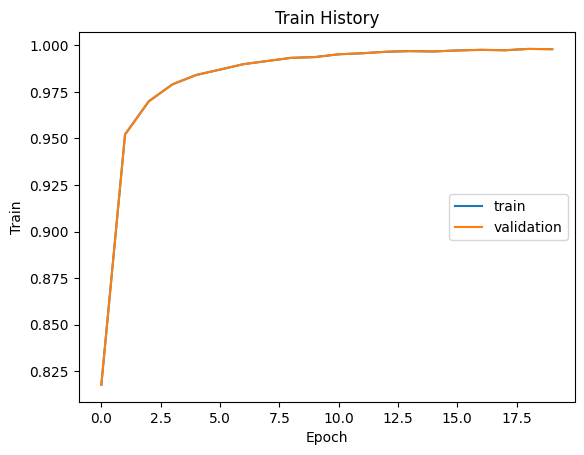

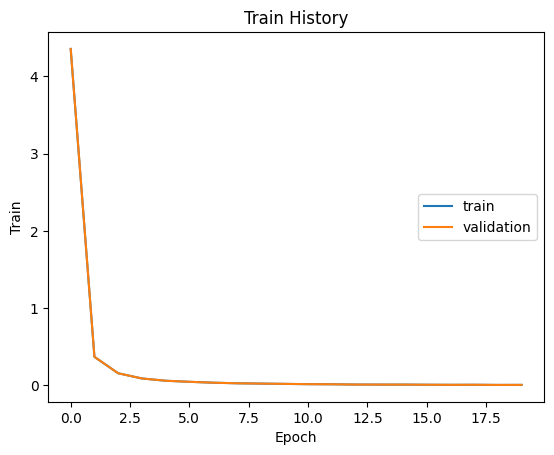

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
(10000, 10)


predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,1,546,0,3,0,1,376,24,12,17
1,0,551,0,10,0,0,13,542,15,4
2,8,692,0,4,3,3,141,120,46,15
3,8,338,0,4,0,1,247,182,2,228
4,4,400,0,1,7,8,162,234,19,147
5,3,456,0,1,0,0,213,153,28,38
6,21,597,0,0,0,2,147,161,12,18
7,9,307,14,2,1,0,166,261,22,246
8,0,652,0,2,1,0,126,129,10,54


In [8]:
#繪製正確性與損失立歷史圖
import matplotlib.pyplot as plt
import numpy as np

def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel('Train')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='center right')
    plt.show()

show_train_history(train_history, 'accuracy', 'accuracy')
show_train_history(train_history, 'loss', 'loss')

# Confusion Matrix混淆矩陣
import pandas as pd
prediction = model.predict(test_data)
prediction_label=np.argmax(prediction,axis=1)
print(test_label.shape)
pd.crosstab(test_label_original, prediction_label, rownames=['label'], colnames=['predict'])